# Ms. Pacman: PPO vs DQN

Notebook này huấn luyện agent chơi **Ms. Pacman (Atari)** bằng hai phương pháp rồi so sánh:

| | **PPO** (Proximal Policy Optimization) | **DQN** (Deep Q-Network) |
|---|---|---|
| Họ thuật toán | Policy gradient (actor-critic) | Value-based |
| Học cái gì | Policy $\pi_\theta(a\mid s)$ và value $V(s)$ | Hàm giá trị hành động $Q(s,a)$ |
| Dữ liệu | **On-policy**: dùng xong rollout là bỏ | **Off-policy**: lưu vào replay buffer, dùng lại nhiều lần |
| Khám phá | Lấy mẫu từ chính policy (có entropy bonus) | $\epsilon$-greedy |
| Song song hoá | Nhiều env chạy cùng lúc | 1 env + replay buffer |

Hai phương pháp dùng **cùng env, cùng tiền xử lý, cùng kiến trúc CNN, cùng ngân sách bước tương tác** để phép so sánh công bằng.

**Mục lục**
1. Môi trường và tiền xử lý
2. Cấu hình chung
3. PPO
4. DQN
5. So sánh
6. Xem agent chơi

> Lưu ý: ảnh Atari khiến việc huấn luyện nặng hơn CartPole hay Acrobot nhiều. Notebook dùng GPU nếu có (`torch.cuda.is_available()`).

## 1. Môi trường và tiền xử lý

`ALE/MsPacman-v5`: agent điều khiển Ms. Pacman ăn chấm (10 điểm), ăn viên năng lượng rồi ăn ma (200 đến 1600 điểm), ăn trái cây, tránh ma. Có 3 mạng, hết mạng thì kết thúc episode.

- **Observation gốc**: ảnh RGB $210\times160\times3$.
- **Action**: `Discrete(9)` gồm NOOP và 8 hướng (UP, RIGHT, LEFT, DOWN và 4 hướng chéo).
- **Reward**: điểm trong game, nên không có "thang chuẩn", mỗi bước có thể là 0, 10, 50, 200...

Pipeline tiền xử lý chuẩn của DeepMind (cả PPO và DQN dùng chung):

1. **Frame skip = 4**: lặp lại action 4 khung hình, cộng dồn reward. Giảm 4 lần số quyết định cần học.
2. **Grayscale + resize 84x84**: bỏ màu và giảm kích thước để mạng nhỏ và nhanh.
3. **Frame stack = 4**: xếp 4 frame gần nhất thành tensor $4\times84\times84$. Một frame đơn không cho biết hướng di chuyển của ma, 4 frame thì có.
4. **No-op reset (tối đa 30)**: đầu episode chờ ngẫu nhiên vài bước để mỗi ván bắt đầu hơi khác nhau.
5. **Reward thang log** $\ln(1+r/10)$ và **mất mạng = hết episode**: chỉ dùng **khi học** (xem ghi chú bên dưới). Khi **báo cáo** vẫn dùng điểm thật.

Ghi chú: tắt sticky action (`repeat_action_probability=0`) cho đơn giản.

**Khi học** (PPO và DQN) có hai thay đổi so với khi chấm điểm:
- **Mất mạng = kết thúc episode** (`EpisodicLife`): chỉ tín hiệu học bị cắt ở đó, game thật chỉ reset khi hết 3 mạng. Nhờ vậy cái chết có hậu quả rõ ràng (mất hết reward tương lai) thay vì chỉ "ngầm" mất chấm.
- **Reward thang log** thay cho `sign(r)`: $r' = \ln(1 + r/10)$. Chấm 10 → 0.69, viên năng lượng 50 → 1.79, ma 200/400/800/1600 → 3.0/3.7/4.4/5.1. Với `sign(r)` thì ăn ma 1600 điểm cũng chỉ bằng ăn một chấm nên agent không có lý do để đuổi ma.

Khi **đánh giá / báo cáo** vẫn chạy game đầy đủ 3 mạng và dùng điểm thật.

In [2]:
import time, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import gymnasium as gym
import ale_py            # đăng ký các env ALE/...
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True                  # chọn kernel conv nhanh nhất cho kích thước cố định
    torch.backends.cuda.matmul.allow_tf32 = True           # TF32 trên GPU Ampere trở lên
    torch.backends.cudnn.allow_tf32 = True

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(0)

device: cuda | NVIDIA GeForce RTX 3070 Ti Laptop GPU


Dùng `gym.Wrapper` để "định nghĩa" lại policy của env, bao gồm terminate khi bị ma ăn thay vì có 3 mạng như bản gốc.

obs: (4, 84, 84) uint8 | actions: 9
['NOOP', 'UP', 'RIGHT', 'LEFT', 'DOWN', 'UPRIGHT', 'UPLEFT', 'DOWNRIGHT', 'DOWNLEFT']


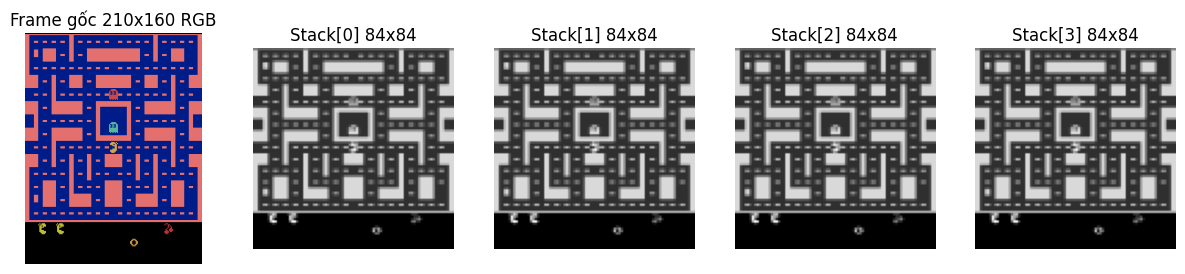

In [3]:
ENV_ID = "ALE/MsPacman-v5"

class EpisodicLife(gym.Wrapper):
    """Dùng khi HỌC: mất một mạng thì báo terminated=True để agent thấy cái chết có giá.
    Game thật chỉ reset khi hết mạng (lúc đó điểm cả ván nằm trong info["game_score"])."""
    def __init__(self, env):
        super().__init__(env)
        self.lives, self.real_done, self.score = 0, True, 0.0

    def step(self, action):
        obs, r, term, trunc, info = self.env.step(action)
        self.score += r
        self.real_done = term or trunc
        lives = self.env.unwrapped.ale.lives()
        if 0 < lives < self.lives:
            term = True                                    # mất mạng nhưng game chưa hết
        self.lives = lives
        if self.real_done:
            info["game_score"] = self.score
        return obs, r, term, trunc, info

    def reset(self, **kwargs):
        if self.real_done:
            obs, info = self.env.reset(**kwargs); self.score = 0.0
        else:                                              # chưa hết game: đi tiếp 1 bước NOOP thay vì reset thật
            obs, r, term, trunc, info = self.env.step(0)
            self.score += r
            if term or trunc:
                obs, info = self.env.reset(**kwargs); self.score = 0.0
        self.real_done = False
        self.lives = self.env.unwrapped.ale.lives()
        return obs, info

def make_env(render_mode=None, episodic_life=False):
    import ale_py                                          # để process con cũng đăng ký được env ALE
    env = gym.make(ENV_ID, frameskip=1, repeat_action_probability=0.0,
                   full_action_space=False, render_mode=render_mode)
    # frame_skip=4, grayscale, resize 84x84, noop reset
    env = gym.wrappers.AtariPreprocessing(env, noop_max=30, frame_skip=4, screen_size=84,
                                          terminal_on_life_loss=False, grayscale_obs=True,
                                          scale_obs=False)
    if episodic_life:
        env = EpisodicLife(env)
    return gym.wrappers.FrameStack(env, 4)     # (4, 84, 84) uint8

def _env_fn(human):
    return lambda: make_env("human" if human else None, episodic_life=True)

class PipelinedEnvs:
    """Env song song dùng khi học (mất mạng = done), chia thành n_groups nhóm chạy xen kẽ.
    Trong lúc emulator (CPU) đang chạy nhóm này thì GPU tính action cho nhóm kia, nên CPU và GPU không chờ nhau.
    render=False: mỗi env một process riêng (AsyncVectorEnv) để dùng hết các nhân CPU.
    render=True : chạy tuần tự trong 1 process và mở cửa sổ game ở env số 0 (chậm, chỉ để xem)."""
    def __init__(self, n_envs, n_groups=2, render=False):
        assert n_envs % n_groups == 0
        self.G, self.gs, self.n = n_groups, n_envs // n_groups, n_envs
        cls = gym.vector.SyncVectorEnv if render else gym.vector.AsyncVectorEnv
        self.envs = [cls([_env_fn(render and g == 0 and i == 0) for i in range(self.gs)]) for g in range(n_groups)]
        self.slices = [slice(g * self.gs, (g + 1) * self.gs) for g in range(n_groups)]

    def reset(self, seed=0):
        return np.concatenate([e.reset(seed=seed + g * self.gs)[0] for g, e in enumerate(self.envs)])

    def send(self, g, actions):
        self.envs[g].step_async(actions)

    def recv(self, g):
        """Trả về (obs, reward thật, done, danh sách điểm thật của các ván vừa hết 3 mạng)."""
        obs, reward, term, trunc, infos = self.envs[g].step_wait()
        return obs, reward, np.logical_or(term, trunc), pop_game_scores(infos)

    def close(self):
        for e in self.envs:
            e.close()

def scale_reward(r):
    """Reward thang log dùng khi học: chấm 10 -> 0.69, viên năng lượng 50 -> 1.79, ma 200..1600 -> 3.0..5.1."""
    return np.log1p(np.asarray(r, dtype=np.float32) / 10.0)

GHOST_REWARDS = (200, 400, 800, 1600)     # ăn ma liên tiếp trong một viên năng lượng

def count_events(reward):
    """Đếm theo reward THẬT (chưa scale) của một bước: (số viên năng lượng = 50, số con ma ăn được).
    Chỉ đếm khi reward khớp đúng; hiếm khi hai sự kiện rơi vào cùng 4 frame thì bị bỏ sót.
    Trái cây 200 điểm (màn 2 trở đi) có thể bị tính nhầm là ma, sai số nhỏ."""
    reward = np.asarray(reward)
    return int((reward == 50).sum()), int(np.isin(reward, GHOST_REWARDS).sum())

def pop_game_scores(infos):
    """Lấy điểm thật của các ván vừa kết thúc hẳn (hết 3 mạng) từ info của vector env."""
    out = []
    for fi in infos.get("final_info", []):
        if fi is not None and "game_score" in fi:
            out.append(fi["game_score"])
    return out

env = make_env()
obs, _ = env.reset(seed=0)
N_ACTIONS = env.action_space.n
print("obs:", np.asarray(obs).shape, np.asarray(obs).dtype, "| actions:", N_ACTIONS)
print(env.unwrapped.get_action_meanings())

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(env.unwrapped.ale.getScreenRGB())
axes[0].set_title("Frame gốc 210x160 RGB")
for i in range(4):
    axes[i + 1].imshow(np.asarray(obs)[i], cmap="gray"); axes[i + 1].set_title(f"Stack[{i}] 84x84")
for a in axes: a.axis("off")
plt.show()
env.close()

In [4]:
# Baseline: agent ngẫu nhiên (để biết "không học gì" đạt bao nhiêu điểm)
def random_baseline(n_episodes=5):
    env = make_env(); scores = []
    for ep in range(n_episodes):
        env.reset(seed=ep); done, score = False, 0.0
        while not done:
            _, r, te, tr, _ = env.step(env.action_space.sample())
            score += r; done = te or tr
        scores.append(score)
    env.close()
    return scores

rand_scores = random_baseline(5)
print("Random:", rand_scores, "| mean =", np.mean(rand_scores))

Random: [330.0, 200.0, 100.0, 250.0, 110.0] | mean = 198.0


## 2. Cấu hình chung

Cả hai phương pháp được cho cùng **`TOTAL_STEPS` bước tương tác** (mỗi bước = 1 quyết định = 4 frame game). Mặc định 10 triệu bước (= 40 triệu frame).

Muốn thử nhanh để kiểm tra code chạy thì hạ `TOTAL_STEPS` xuống `50_000`.

**Tốc độ**: nút thắt là CPU chạy emulator Atari, không phải GPU, và trước đây CPU với GPU còn chờ nhau. Vì vậy cả PPO và DQN đều:
- chạy 16 env song song, mỗi env một process (khoảng 6.500 steps/s so với khoảng 1.600 khi chạy tuần tự);
- chia 16 env thành 2 nhóm chạy xen kẽ (`PipelinedEnvs`): GPU tính action cho nhóm này trong lúc emulator chạy nhóm kia; với DQN thì bước cập nhật mạng cũng chạy chồng lên lúc emulator đang chạy;
- dùng TF32 và cuDNN benchmark trên GPU.

**Kiến trúc CNN** (Nature DQN, Mnih 2015), dùng cho cả hai:

```
input (4,84,84) uint8  ->  chia 255
Conv 32 filters 8x8 stride 4 + ReLU    -> (32,20,20)
Conv 64 filters 4x4 stride 2 + ReLU    -> (64, 9, 9)
Conv 64 filters 3x3 stride 1 + ReLU    -> (64, 7, 7)
Flatten (3136) -> Linear 512 + ReLU
```
Phần "đầu ra" khác nhau: PPO có hai đầu (actor và critic), DQN có một đầu Q cho 9 action.

In [5]:
TOTAL_STEPS = 10_000_000         # ngân sách bước tương tác, dùng cho cả PPO và DQN
N_ENVS = 16                      # số env song song (máy 20 luồng CPU)

def make_cnn():
    return nn.Sequential(
        nn.Conv2d(4, 32, 8, stride=4), nn.ReLU(),
        nn.Conv2d(32, 64, 4, stride=2), nn.ReLU(),
        nn.Conv2d(64, 64, 3, stride=1), nn.ReLU(),
        nn.Flatten(),
        nn.Linear(64 * 7 * 7, 512), nn.ReLU(),
    )

def moving_avg(x, w):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid") if len(x) >= w else x

def evaluate(act_fn, n_episodes=10, max_steps=4500, seed=1000):
    """Chạy act_fn(obs: np.ndarray (4,84,84)) -> int, trả về danh sách điểm thật (không clip)."""
    env = make_env(); scores = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep); score, done, steps = 0.0, False, 0
        while not done and steps < max_steps:
            obs, r, te, tr, _ = env.step(act_fn(np.asarray(obs)))
            score += r; done = te or tr; steps += 1
        scores.append(score)
    env.close()
    return scores

def watch(act_fn, episodes=2, max_steps=4500):
    """Mở cửa sổ game (cần màn hình) để xem act_fn chơi."""
    env = make_env(render_mode="human")
    for ep in range(episodes):
        obs, _ = env.reset(); score, done, steps = 0.0, False, 0
        while not done and steps < max_steps:
            obs, r, te, tr, _ = env.step(act_fn(np.asarray(obs)))
            score += r; done = te or tr; steps += 1
        print(f"[watch] episode {ep + 1}: score = {score:.0f}")
    env.close()

## 3. PPO

### 3.1 Ý tưởng

PPO học trực tiếp một **policy** $\pi_\theta(a\mid s)$ (xác suất chọn từng action) và một **critic** $V_\phi(s)$ (ước lượng tổng reward tương lai). Hai thành phần dùng chung phần CNN.

**Vòng lặp mỗi "update":**

1. **Thu thập (rollout)**: $N$ env chạy song song, mỗi env $T$ bước bằng policy hiện tại. Được $N\cdot T$ mẫu và lưu lại $\log\pi_{old}(a\mid s)$.
2. **Tính advantage bằng GAE**: advantage $\hat A_t$ cho biết action ở bước $t$ tốt hơn mức "trung bình" bao nhiêu.
$$\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t),\qquad \hat A_t = \sum_{l\ge 0} (\gamma\lambda)^l\,\delta_{t+l}$$
3. **Cập nhật** $K$ epoch trên chính rollout đó, chia minibatch, tối thiểu hoá loss gồm 3 phần.

**Mục tiêu bị cắt (clipped objective)**: gọi tỷ lệ $r_t(\theta)=\dfrac{\pi_\theta(a_t\mid s_t)}{\pi_{old}(a_t\mid s_t)}$
$$L^{CLIP}=\mathbb{E}\Big[\min\big(r_t\hat A_t,\ \mathrm{clip}(r_t,1-\varepsilon,1+\varepsilon)\hat A_t\big)\Big]$$
Nếu policy mới đi quá xa policy cũ (tỷ lệ ra ngoài $[1-\varepsilon,1+\varepsilon]$) thì gradient bị chặn. Nhờ đó có thể cập nhật nhiều epoch trên cùng dữ liệu mà không bị "văng" khỏi vùng tin cậy.

**Loss tổng**:
$$L = -L^{CLIP} + c_1\,(V_\phi(s_t)-\hat R_t)^2 - c_2\,H[\pi_\theta]$$
- $c_1$: trọng số value loss (critic bắt kịp return $\hat R_t=\hat A_t+V(s_t)$).
- $c_2$: **entropy bonus**, giữ policy chưa quá deterministic để còn khám phá.

### 3.2 Siêu tham số (theo thiết lập chuẩn cho Atari)

| Tham số | Giá trị | Ý nghĩa |
|---|---|---|
| `n_envs` | 16 | số env song song (mỗi env một process) |
| `n_steps` | 128 | số bước mỗi env trong một rollout (batch = 16x128 = 2048) |
| `epochs` | 4 | số lần lặp trên mỗi rollout |
| `n_minibatches` | 4 | minibatch = 512 |
| `lr` | 2.5e-4, giảm tuyến tính về 0 | |
| `clip` | 0.1 | $\varepsilon$ |
| `gamma`, `lam` | 0.99, 0.95 | |
| `c1`, `c2` | 0.5, 0.01 | |

Khi học: mất mạng = kết thúc episode, reward thang log (xem mục 1). Điểm ghi lại trong log là điểm thật của cả ván 3 mạng.

In [6]:
class ActorCriticCNN(nn.Module):
    def __init__(self, n_actions):
        super().__init__()
        self.cnn = make_cnn()
        self.actor = nn.Linear(512, n_actions)
        self.critic = nn.Linear(512, 1)
        # khởi tạo trực giao (chuẩn của PPO): actor nhỏ để policy ban đầu gần đều
        for m in self.cnn:
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.orthogonal_(m.weight, np.sqrt(2)); nn.init.zeros_(m.bias)
        nn.init.orthogonal_(self.actor.weight, 0.01); nn.init.zeros_(self.actor.bias)
        nn.init.orthogonal_(self.critic.weight, 1.0); nn.init.zeros_(self.critic.bias)

    def forward(self, x):                       # x: uint8 (B,4,84,84)
        h = self.cnn(x.float() / 255.0)
        return Categorical(logits=self.actor(h)), self.critic(h).squeeze(-1)

    @torch.no_grad()
    def act(self, x):
        """Chọn action khi thu rollout, trả về (action, log_prob, value). Lấy mẫu bằng Gumbel-max,
        cùng phân phối với Categorical nhưng ít op hơn nên nhanh hơn khi gọi từng bước nhỏ."""
        h = self.cnn(x.float() / 255.0)
        logits = self.actor(h)
        gumbel = -torch.log(-torch.log(torch.rand_like(logits).clamp_(1e-10, 1 - 1e-7)))
        a = (logits + gumbel).argmax(-1)
        logp = torch.log_softmax(logits, -1).gather(1, a[:, None]).squeeze(1)
        return a, logp, self.critic(h).squeeze(-1)

In [23]:
def train_ppo(total_steps, n_envs=N_ENVS, n_steps=128, epochs=4, n_minibatches=4, lr=2.5e-4,
              gamma=0.99, lam=0.95, clip_eps=0.1, c1=0.5, c2=0.01, max_grad=0.5,
              seed=0, log_every=50, save_path=None, save_every=200, model=None,
              watch_every=0, watch_episodes=1, render=False):
    """Train PPO trên MsPacman. Trả về (model, log, ep_log).
    ep_log: danh sách (global_step, điểm thật của cả ván 3 mạng)."""
    set_seed(seed)
    # render=True: env số 0 mở cửa sổ game, chạy tuần tự (chậm) để quan sát agent
    envs = PipelinedEnvs(n_envs, render=render)
    obs = torch.as_tensor(envs.reset(seed=seed), device=device)

    model = (model or ActorCriticCNN(N_ACTIONS)).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, eps=1e-5)

    batch = n_envs * n_steps
    mb_size = batch // n_minibatches
    n_updates = total_steps // batch
    B_obs = torch.zeros((n_steps, n_envs, 4, 84, 84), dtype=torch.uint8, device=device)
    B_act = torch.zeros((n_steps, n_envs), dtype=torch.long, device=device)
    B_logp = torch.zeros((n_steps, n_envs), device=device)
    B_rew = torch.zeros((n_steps, n_envs), device=device)
    B_done = torch.zeros((n_steps, n_envs), device=device)
    B_val = torch.zeros((n_steps, n_envs), device=device)

    ep_log = []
    log = {"step": [], "ent": [], "kl": [], "clipfrac": [], "v_loss": [], "pg_loss": [], "pellets": [], "ghosts": []}
    global_step, t0, n_pellet, n_ghost = 0, time.time(), 0, 0      # n_pellet / n_ghost: tổng số viên năng lượng / ma đã ăn
    print(f"PPO: {n_updates} updates x {batch} mẫu = {n_updates * batch:,} bước, {n_envs} env song song")

    for update in range(n_updates):
        for g in optimizer.param_groups:                       # giảm lr tuyến tính
            g["lr"] = lr * (1.0 - update / n_updates)

        # ---- Pha 1: thu thập rollout (2 nhóm env xen kẽ: GPU chọn action nhóm này khi CPU đang chạy nhóm kia) ----
        def launch(t, g):
            sl = envs.slices[g]
            a, logp, value = model.act(obs[sl])
            B_obs[t, sl], B_act[t, sl], B_logp[t, sl], B_val[t, sl] = obs[sl], a, logp, value
            envs.send(g, a.cpu().numpy())

        for g in range(envs.G):
            launch(0, g)
        for t in range(n_steps):
            for g in range(envs.G):
                sl = envs.slices[g]
                next_obs, reward, done, scores = envs.recv(g)
                global_step += envs.gs
                ep_log.extend((global_step, s) for s in scores)    # điểm thật của ván vừa hết 3 mạng
                p, gh = count_events(reward); n_pellet += p; n_ghost += gh
                B_rew[t, sl] = torch.as_tensor(scale_reward(reward), device=device)
                B_done[t, sl] = torch.as_tensor(done, dtype=torch.float32, device=device)
                obs[sl] = torch.as_tensor(next_obs, device=device)
                if t + 1 < n_steps:
                    launch(t + 1, g)

        # ---- Pha 2: GAE ----
        with torch.no_grad():
            last_value = model(obs)[1]
        adv = torch.zeros_like(B_rew)
        gae = torch.zeros(n_envs, device=device)
        for t in reversed(range(n_steps)):
            next_value = last_value if t == n_steps - 1 else B_val[t + 1]
            nonterm = 1.0 - B_done[t]
            delta = B_rew[t] + gamma * next_value * nonterm - B_val[t]
            gae = delta + gamma * lam * nonterm * gae
            adv[t] = gae
        returns = adv + B_val

        # ---- Pha 3: cập nhật PPO ----
        f_obs = B_obs.reshape(batch, 4, 84, 84)
        f_act, f_logp = B_act.reshape(-1), B_logp.reshape(-1)
        f_adv, f_ret = adv.reshape(-1), returns.reshape(-1)
        for _ in range(epochs):
            perm = torch.randperm(batch, device=device)
            for i in range(0, batch, mb_size):
                idx = perm[i:i + mb_size]
                dist, value = model(f_obs[idx])
                logp = dist.log_prob(f_act[idx])
                ratio = torch.exp(logp - f_logp[idx])
                a = f_adv[idx]; a = (a - a.mean()) / (a.std() + 1e-8)

                pg_loss = -torch.min(ratio * a, torch.clamp(ratio, 1 - clip_eps, 1 + clip_eps) * a).mean()
                v_loss = ((value - f_ret[idx]) ** 2).mean()
                entropy = dist.entropy().mean()
                loss = pg_loss + c1 * v_loss - c2 * entropy

                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_grad)
                optimizer.step()

        with torch.no_grad():
            kl = (f_logp[idx] - logp).mean().item()
            cf = ((ratio - 1).abs() > clip_eps).float().mean().item()
        for k, v in zip(log, [global_step, entropy.item(), kl, cf, v_loss.item(), pg_loss.item(), n_pellet, n_ghost]):
            log[k].append(v)

        if watch_every and global_step // watch_every > (global_step - batch) // watch_every:
            def _act(o):
                with torch.no_grad():
                    return model(torch.as_tensor(o, device=device).unsqueeze(0))[0].sample().item()
            print(f"[watch] step {global_step:,}")
            watch(_act, watch_episodes)

        if save_path and (update + 1) % save_every == 0:       # lưu giữa chừng, phòng treo máy khi chạy lâu
            torch.save(model.state_dict(), save_path)

        if (update + 1) % log_every == 0 or update == n_updates - 1:
            recent = [r for _, r in ep_log[-20:]]
            print(f"Update {update + 1}/{n_updates} | step {global_step:,} | "
                  f"avg score(20) {np.mean(recent) if recent else float('nan'):.0f} | "
                  f"viên NL {n_pellet:,} | ma {n_ghost:,} | entropy {entropy.item():.3f} | KL {kl:.4f} | clipfrac {cf:.3f} | "
                  f"{global_step / (time.time() - t0):.0f} steps/s")

    envs.close()
    if save_path:
        torch.save(model.state_dict(), save_path)
    return model, log, ep_log

In [25]:
ppo_model, ppo_log, ppo_eps = train_ppo(2_000_000, save_path="ms_pacman_ppo.pt")
# Xem trực tiếp trong lúc train: thêm render=True (chậm, chạy tuần tự). Hoặc watch_every=500_000 để thỉnh thoảng mở 1 ván
np.save("ms_pacman_ppo_episodes.npy", np.array(ppo_eps))
np.save("ms_pacman_ppo_log.npy", ppo_log, allow_pickle=True)

PPO: 976 updates x 2048 mẫu = 1,998,848 bước, 16 env song song
Update 50/976 | step 102,400 | avg score(20) 492 | viên NL 116 | ma 63 | entropy 1.881 | KL 0.0003 | clipfrac 0.076 | 1898 steps/s
Update 100/976 | step 204,800 | avg score(20) 650 | viên NL 283 | ma 181 | entropy 1.746 | KL 0.0006 | clipfrac 0.090 | 1907 steps/s
Update 150/976 | step 307,200 | avg score(20) 754 | viên NL 453 | ma 305 | entropy 1.561 | KL 0.0007 | clipfrac 0.094 | 1868 steps/s
Update 200/976 | step 409,600 | avg score(20) 930 | viên NL 617 | ma 426 | entropy 1.460 | KL 0.0011 | clipfrac 0.084 | 1892 steps/s
Update 250/976 | step 512,000 | avg score(20) 690 | viên NL 750 | ma 521 | entropy 1.550 | KL 0.0043 | clipfrac 0.113 | 1900 steps/s
Update 300/976 | step 614,400 | avg score(20) 602 | viên NL 882 | ma 611 | entropy 1.687 | KL 0.0053 | clipfrac 0.504 | 1906 steps/s
Update 350/976 | step 716,800 | avg score(20) 741 | viên NL 1,012 | ma 699 | entropy 1.523 | KL 0.0002 | clipfrac 0.219 | 1917 steps/s
Update

In [7]:
from pathlib import Path

# Thư mục lưu = thư mục chứa notebook này (Jupyter/VS Code đặt cwd ở đây)
SAVE_DIR = Path.cwd()
PPO_MODEL = SAVE_DIR / "ms_pacman_ppo.pt"
PPO_EPS   = SAVE_DIR / "ms_pacman_ppo_episodes.npy"
PPO_LOG   = SAVE_DIR / "ms_pacman_ppo_log.npy"
print("SAVE_DIR:", SAVE_DIR)

def save_ppo(model, log, eps):
    torch.save(model.state_dict(), PPO_MODEL)
    np.save(PPO_EPS, np.array(eps))
    np.save(PPO_LOG, log, allow_pickle=True)
    print("Đã lưu:", *[f"\n  {p}" for p in (PPO_MODEL, PPO_EPS, PPO_LOG)])

def load_ppo():
    model = ActorCriticCNN(N_ACTIONS).to(device)
    model.load_state_dict(torch.load(PPO_MODEL, map_location=device))
    model.eval()
    eps = [tuple(x) for x in np.load(PPO_EPS)]
    log = np.load(PPO_LOG, allow_pickle=True).item()
    print(f"Đã nạp PPO từ {SAVE_DIR} | {len(eps)} episode, {log['step'][-1]:,} bước")
    return model, log, eps

def play_ppo(model, episodes=2, greedy=False, max_steps=4500):
    """Mở cửa sổ game (cần màn hình) cho PPO chơi, in điểm từng ván, trả về danh sách điểm.
    greedy=False: lấy mẫu từ policy (giống lúc train/đánh giá). greedy=True: luôn chọn action xác suất cao nhất."""
    model.eval()
    def act(obs):
        with torch.no_grad():
            dist, _ = model(torch.as_tensor(obs, device=device).unsqueeze(0))
            return dist.probs.argmax(1).item() if greedy else dist.sample().item()
    env = make_env(render_mode="human")
    scores = []
    try:
        for ep in range(episodes):
            obs, _ = env.reset(); score, done, steps = 0.0, False, 0
            while not done and steps < max_steps:
                obs, r, te, tr, _ = env.step(act(np.asarray(obs)))
                score += r; done = te or tr; steps += 1
            scores.append(score)
            print(f"[play] ván {ep + 1}: {score:.0f} điểm ({steps} bước)")
    finally:
        env.close()
    return scores

if "ppo_model" in globals():       # vừa train xong, model còn trong bộ nhớ -> lưu lại
    save_ppo(ppo_model, ppo_log, ppo_eps)
else:                              # kernel mới khởi động lại -> nạp từ file
    ppo_model, ppo_log, ppo_eps = load_ppo()

# play_ppo(ppo_model, episodes=2)                # xem AI chơi (lấy mẫu từ policy)
play_ppo(ppo_model, episodes=2, greedy=True)   # hoặc chọn action tốt nhất

SAVE_DIR: d:\FPT Uni\REL301m\rel_ms_pacman\notebooks
Đã nạp PPO từ d:\FPT Uni\REL301m\rel_ms_pacman\notebooks | 3158 episode, 1,998,848 bước
[play] ván 1: 560 điểm (626 bước)


: 

## 4. DQN

### 4.1 Ý tưởng

DQN học hàm giá trị hành động $Q_\theta(s,a)$ = tổng reward kỳ vọng nếu ở trạng thái $s$, làm action $a$ rồi chơi tối ưu. Khi có $Q$, policy đơn giản là $a=\arg\max_a Q(s,a)$.

Học bằng phương trình Bellman: $Q(s,a)\approx r+\gamma\max_{a'}Q(s',a')$. Với mạng neural, cách học này dễ mất ổn định, nên DQN thêm hai mẹo:

1. **Replay buffer**: lưu các chuyển tiếp $(s,a,r,s',\text{done})$ và học từ minibatch **ngẫu nhiên**. Phá tương quan giữa các mẫu liên tiếp và tái sử dụng dữ liệu nhiều lần (đây là điểm khác lớn với PPO).
2. **Target network** $Q_{\theta^-}$: bản sao "đóng băng" của mạng, chỉ cập nhật định kỳ. Dùng để tính đích học nên đích không dịch chuyển mỗi bước.

$$y = r + \gamma\,(1-\text{done})\,\max_{a'}Q_{\theta^-}(s',a'),\qquad L(\theta)=\mathrm{Huber}\big(Q_\theta(s,a),\,y\big)$$

**Khám phá bằng $\epsilon$-greedy**: với xác suất $\epsilon$ chọn action ngẫu nhiên, ngược lại chọn $\arg\max Q$. $\epsilon$ giảm tuyến tính từ 1.0 xuống 0.05 trong 5% đầu tổng số bước (500k bước khi `TOTAL_STEPS` = 10M).

### 4.2 Replay buffer tiết kiệm bộ nhớ

Mỗi quan sát là stack 4 frame, nên lưu thẳng $(s,s')$ sẽ tốn $2\times4\times84\times84$ byte mỗi chuyển tiếp. Cách làm ở đây: **chỉ lưu frame mới nhất** (84x84 = 7 KB) rồi dựng lại stack từ 4 frame liền trước của **cùng env đó**. Ở đầu episode, frame đầu được lặp lại (giống `FrameStack`). Buffer 200k mẫu chỉ tốn khoảng 1.4 GB RAM.

### 4.3 Siêu tham số (theo thiết lập DQN Atari)

| Tham số | Giá trị |
|---|---|
| `n_envs` | 16 (mỗi vòng lặp thu 16 chuyển tiếp) |
| `buffer_size` | 200,000 |
| `batch_size` | 128 |
| `updates_per_iter` | 1 bước gradient mỗi vòng (= 128 mẫu / 16 chuyển tiếp, bằng tỷ lệ tái sử dụng 8 của DQN gốc: batch 32 mỗi 4 bước; batch lớn dùng GPU hiệu quả hơn) |
| `lr` | 1e-4 (Adam) |
| `gamma` | 0.99 |
| `learning_starts` | 20,000 bước thu thập ngẫu nhiên trước khi học |
| `target_update` | 10,000 bước env |
| $\epsilon$ | 1.0 về 0.05 trong 5% đầu tổng số bước |
| loss | Huber (SmoothL1), clip grad norm 10 |

Đây là DQN gốc, không dùng Double DQN, Dueling hay Prioritized Replay. Mất mạng = kết thúc episode và reward thang log, như PPO.

In [ ]:
class QNetwork(nn.Module):
    def __init__(self, n_actions):
        super().__init__()
        self.cnn = make_cnn()
        self.head = nn.Linear(512, n_actions)

    def forward(self, x):                       # x: uint8 (B,4,84,84)
        return self.head(self.cnn(x.float() / 255.0))


class VecFrameReplayBuffer:
    """Replay buffer cho n_envs env song song, chỉ lưu frame mới nhất của mỗi bước và dựng lại stack 4 frame khi lấy mẫu.
    Mỗi env là một "cột" riêng nên stack không bao giờ trộn frame của hai env khác nhau."""
    def __init__(self, capacity, n_envs):
        self.n, self.T = n_envs, capacity // n_envs
        self.frames = np.zeros((self.T, n_envs, 84, 84), dtype=np.uint8)
        self.act = np.zeros((self.T, n_envs), dtype=np.int64)
        self.rew = np.zeros((self.T, n_envs), dtype=np.float32)
        self.done = np.zeros((self.T, n_envs), dtype=np.float32)
        self.ep_start = np.zeros((self.T, n_envs), dtype=np.int64)   # thời điểm tuyệt đối của frame đầu episode
        self.t = 0                                                   # số bước thời gian đã ghi
        self.cur_start = np.zeros(n_envs, dtype=np.int64)
        self.offs = np.arange(-3, 1)

    def add(self, obs, action, reward, done, is_first):    # mỗi tham số có độ dài n_envs
        i = self.t % self.T
        self.cur_start[is_first] = self.t
        self.frames[i] = obs[:, -1]
        self.act[i], self.rew[i], self.done[i], self.ep_start[i] = action, reward, done, self.cur_start
        self.t += 1

    def __len__(self):
        return min(self.t, self.T) * self.n

    def _stack(self, P, E):
        S = self.ep_start[P % self.T, E]
        idx = np.maximum(P[:, None] + self.offs[None, :], S[:, None]) % self.T
        return self.frames[idx, E[:, None]]                         # (B,4,84,84)

    def sample(self, batch_size):
        lo = max(0, self.t - self.T + 3)                            # frame cũ hơn đã bị ghi đè
        hi = self.t - 2                                             # cần có sẵn P+1
        P = np.random.randint(lo, hi + 1, size=batch_size)
        E = np.random.randint(0, self.n, size=batch_size)
        i = P % self.T
        to_t = lambda a: torch.as_tensor(a, device=device)
        return (to_t(self._stack(P, E)), to_t(self.act[i, E]), to_t(self.rew[i, E]),
                to_t(self._stack(P + 1, E)), to_t(self.done[i, E]))

In [ ]:
def train_dqn(total_steps, n_envs=N_ENVS, buffer_size=200_000, batch_size=128, updates_per_iter=1,
              lr=1e-4, gamma=0.99, learning_starts=20_000, target_update=10_000,
              eps_start=1.0, eps_end=0.05, eps_frac=0.05, max_grad=10.0,
              seed=0, log_every=100_000, save_path=None, save_every=500_000, model=None,
              watch_every=0, watch_episodes=1, render=False):
    """Train DQN trên MsPacman. Trả về (model, log, ep_log).
    ep_log: danh sách (step, điểm thật của cả ván 3 mạng)."""
    set_seed(seed)
    envs = PipelinedEnvs(n_envs, render=render)
    obs = envs.reset(seed=seed)

    q = (model or QNetwork(N_ACTIONS)).to(device)
    q_target = copy.deepcopy(q).eval()
    optimizer = optim.Adam(q.parameters(), lr=lr)
    buffer = VecFrameReplayBuffer(buffer_size, n_envs)

    eps_steps = int(eps_frac * total_steps)
    ep_log, first = [], np.ones(n_envs, dtype=bool)                # first[e]: obs hiện tại của env e là frame đầu episode
    pend = [None] * envs.G                                         # (obs, action, is_first) đã gửi đi, chờ kết quả
    trans = [None] * envs.G                                        # chuyển tiếp đã hoàn tất của vòng này
    log = {"step": [], "loss": [], "q_mean": [], "eps": [], "pellets": [], "ghosts": []}
    n_pellet = n_ghost = 0                                         # tổng số viên năng lượng / ma đã ăn
    loss_acc, q_acc, n_acc = torch.zeros((), device=device), torch.zeros((), device=device), 0   # cộng dồn trên GPU, đỡ sync
    t0 = time.time()
    n_iters = total_steps // n_envs
    next_target, next_log, next_save, next_watch = target_update, log_every, save_every, watch_every
    print(f"DQN: {n_iters * n_envs:,} bước, {n_envs} env song song, buffer {buffer_size:,}, epsilon giảm trong {eps_steps:,} bước đầu")

    def launch(g, eps):
        """Chọn action epsilon-greedy cho nhóm g rồi gửi đi, emulator chạy trong khi GPU làm việc khác."""
        sl = envs.slices[g]
        with torch.no_grad():
            greedy = q(torch.as_tensor(obs[sl], device=device)).argmax(1).cpu().numpy()
        action = np.where(np.random.random(envs.gs) < eps, np.random.randint(0, N_ACTIONS, size=envs.gs), greedy)
        pend[g] = (obs[sl].copy(), action, first[sl].copy())
        envs.send(g, action)

    for g in range(envs.G):
        launch(g, eps_start)
    for it in range(1, n_iters + 1):
        step = it * n_envs
        eps = max(eps_end, eps_start - (eps_start - eps_end) * step / eps_steps)
        for g in range(envs.G):                                # nhận kết quả nhóm g rồi gửi ngay action kế tiếp
            sl = envs.slices[g]
            next_obs, reward, done, scores = envs.recv(g)
            ep_log.extend((step, s) for s in scores)           # điểm thật của ván vừa hết 3 mạng
            p, gh = count_events(reward); n_pellet += p; n_ghost += gh
            p_obs, p_act, p_first = pend[g]
            trans[g] = (p_obs, p_act, scale_reward(reward), done.astype(np.float32), p_first)
            obs[sl], first[sl] = next_obs, done
            launch(g, eps)
        buffer.add(*[np.concatenate(x) for x in zip(*trans)])  # ghi cả 16 env của bước này cùng lúc

        # bước cập nhật mạng chạy trong lúc emulator đang chạy bước kế tiếp
        if step >= learning_starts:
            for _ in range(updates_per_iter):
                s, a, r, s2, d = buffer.sample(batch_size)
                with torch.no_grad():
                    y = r + gamma * (1 - d) * q_target(s2).max(1)[0]
                q_sa = q(s).gather(1, a.unsqueeze(1)).squeeze(1)
                loss = nn.functional.smooth_l1_loss(q_sa, y)
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(q.parameters(), max_grad)
                optimizer.step()
                loss_acc += loss.detach(); q_acc += q_sa.detach().mean(); n_acc += 1

        if step >= next_target:
            q_target.load_state_dict(q.state_dict()); next_target += target_update

        if watch_every and step >= next_watch:
            next_watch += watch_every
            def _act(o):
                if random.random() < 0.05:
                    return random.randrange(N_ACTIONS)
                with torch.no_grad():
                    return q(torch.as_tensor(o, device=device).unsqueeze(0)).argmax(1).item()
            print(f"[watch] step {step:,}")
            watch(_act, watch_episodes)

        if save_path and step >= next_save:                    # lưu giữa chừng, phòng treo máy khi chạy lâu
            torch.save(q.state_dict(), save_path); next_save += save_every

        if step >= next_log:
            next_log += log_every
            recent = [r for _, r in ep_log[-20:]]
            log["step"].append(step); log["eps"].append(eps); log["pellets"].append(n_pellet); log["ghosts"].append(n_ghost)
            log["loss"].append(loss_acc.item() / n_acc if n_acc else float("nan"))
            log["q_mean"].append(q_acc.item() / n_acc if n_acc else float("nan"))
            loss_acc.zero_(); q_acc.zero_(); n_acc = 0
            print(f"Step {step:,}/{total_steps:,} | avg score(20) {np.mean(recent) if recent else float('nan'):.0f} | "
                  f"viên NL {n_pellet:,} | ma {n_ghost:,} | eps {eps:.2f} | loss {log['loss'][-1]:.4f} | Q {log['q_mean'][-1]:.2f} | "
                  f"{step / (time.time() - t0):.0f} steps/s")

    for g in range(envs.G):                                    # nhận nốt các bước đang chạy dở trước khi đóng env
        envs.recv(g)
    envs.close()
    if save_path:
        torch.save(q.state_dict(), save_path)
    return q, log, ep_log

In [ ]:
dqn_model, dqn_log, dqn_eps = train_dqn(TOTAL_STEPS, save_path="ms_pacman_dqn.pt")
# Xem trực tiếp trong lúc train: thêm render=True (chậm, chạy tuần tự). Hoặc watch_every=500_000 để thỉnh thoảng mở 1 ván
np.save("ms_pacman_dqn_episodes.npy", np.array(dqn_eps))
np.save("ms_pacman_dqn_log.npy", dqn_log, allow_pickle=True)

## 5. So sánh PPO và DQN

Hai cách đo:

1. **Đường học (learning curve)**: điểm của từng episode trong lúc huấn luyện theo số bước, làm mượt bằng trung bình trượt. Lưu ý điểm lúc train của DQN còn bị $\epsilon$-greedy kéo xuống, còn PPO luôn lấy mẫu từ policy.
2. **Đánh giá cuối**: chạy model cuối cùng trên cùng các seed. PPO lấy mẫu từ policy, DQN dùng $\epsilon=0.05$ (tránh kẹt do greedy hoàn toàn).

Nếu đã train từ trước và chỉ muốn so sánh, có thể nạp lại model (`ms_pacman_*.pt`) và log (`ms_pacman_*_episodes.npy`) thay vì train lại.

NameError: name 'dqn_eps' is not defined

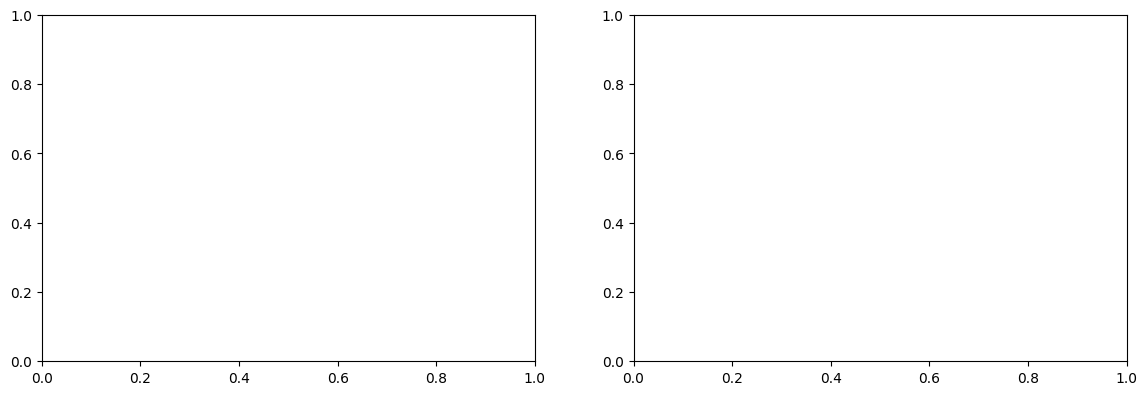

In [33]:
# (tuỳ chọn) nạp lại kết quả đã lưu nếu kernel vừa khởi động lại
# ppo_model = ActorCriticCNN(N_ACTIONS).to(device); ppo_model.load_state_dict(torch.load("ms_pacman_ppo.pt"))
# dqn_model = QNetwork(N_ACTIONS).to(device);       dqn_model.load_state_dict(torch.load("ms_pacman_dqn.pt"))
# ppo_eps = [tuple(x) for x in np.load("ms_pacman_ppo_episodes.npy")]
# dqn_eps = [tuple(x) for x in np.load("ms_pacman_dqn_episodes.npy")]
# ppo_log = np.load("ms_pacman_ppo_log.npy", allow_pickle=True).item()
# dqn_log = np.load("ms_pacman_dqn_log.npy", allow_pickle=True).item()

def curve(eps, w=20):
    steps, rets = zip(*eps)
    return np.array(steps)[w - 1:] if len(rets) >= w else np.array(steps), moving_avg(rets, w)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, eps, color in [("PPO", ppo_eps, "tab:blue"), ("DQN", dqn_eps, "tab:orange")]:
    st, rt = zip(*eps)
    ax[0].scatter(st, rt, s=4, alpha=0.15, color=color)
    x, y = curve(eps); ax[0].plot(x, y, color=color, label=f"{name} (TB trượt 20 ep)")
ax[0].axhline(np.mean(rand_scores), ls="--", color="gray", label="Random")
ax[0].set(title="Điểm theo số bước tương tác", xlabel="Bước env", ylabel="Điểm Ms. Pacman")
ax[0].legend()

for name, log, color in [("PPO", ppo_log, "tab:blue")]:
    ax[1].plot(log["step"], log["ent"], color=color, label="PPO entropy")
ax[1].set(title="PPO: entropy của policy", xlabel="Bước env")
ax[1].legend()
plt.tight_layout(); plt.savefig("ms_pacman_curves.png", dpi=150); plt.show()

# --- Số viên năng lượng và số ma ăn được (theo reward thật), tính trên mỗi 100k bước ---
def events_per_bin(log, total, bin_size=100_000):
    """Từ tổng tích luỹ log["pellets"], log["ghosts"] theo log["step"] -> số sự kiện trong mỗi khoảng bin_size bước."""
    edges = np.arange(0, total + bin_size, bin_size)
    out = {}
    for key in ("pellets", "ghosts"):
        cum = np.interp(edges, np.r_[0, log["step"]], np.r_[0, log[key]])
        out[key] = np.diff(cum)
    return edges[1:], out

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for name, log, color in [("PPO", ppo_log, "tab:blue"), ("DQN", dqn_log, "tab:orange")]:
    x, ev = events_per_bin(log, TOTAL_STEPS)
    ax[0].plot(x, ev["pellets"], color=color, label=name)
    ax[1].plot(x, ev["ghosts"], color=color, label=name)
    ax[2].plot(x, ev["ghosts"] / np.maximum(ev["pellets"], 1), color=color, label=name)
ax[0].set(title="Viên năng lượng ăn được / 100k bước", xlabel="Bước env")
ax[1].set(title="Ma ăn được / 100k bước", xlabel="Bước env")
ax[2].set(title="Ma ăn được trên mỗi viên năng lượng", xlabel="Bước env")
for a in ax: a.legend()
plt.tight_layout(); plt.savefig("ms_pacman_events.png", dpi=150); plt.show()


In [ ]:
def ppo_act(obs):
    with torch.no_grad():
        dist, _ = ppo_model(torch.as_tensor(obs, device=device).unsqueeze(0))
        return dist.sample().item()

def dqn_act(obs, eps=0.05):
    if random.random() < eps:
        return random.randrange(N_ACTIONS)
    with torch.no_grad():
        return dqn_model(torch.as_tensor(obs, device=device).unsqueeze(0)).argmax(1).item()

ppo_model.eval(); dqn_model.eval()
N_EVAL = 10
res = {"Random": rand_scores,
       "PPO": evaluate(ppo_act, N_EVAL),
       "DQN": evaluate(dqn_act, N_EVAL)}

print(f"{'Method':8s} {'mean':>8s} {'std':>8s} {'max':>8s}   (trên {N_EVAL} episode)")
for k, v in res.items():
    print(f"{k:8s} {np.mean(v):8.0f} {np.std(v):8.0f} {np.max(v):8.0f}")

plt.figure(figsize=(6, 4))
plt.boxplot(res.values(), labels=res.keys()); plt.ylabel("Điểm"); plt.title("Đánh giá cuối")
plt.show()

### Nhận xét

Điền sau khi chạy xong, dựa trên đường học và bảng điểm ở trên. Một số điểm nên kiểm tra:

- **Hiệu quả mẫu (sample efficiency)**: DQN dùng lại mỗi mẫu nhiều lần qua replay buffer nên thường cần ít tương tác hơn để đạt cùng mức điểm. PPO bỏ rollout sau 4 epoch nên thường cần nhiều bước hơn.
- **Độ ổn định**: PPO có clip nên đường học thường mượt hơn. DQN dễ dao động (xem `q_mean` và `loss` trong `dqn_log` xem có bùng nổ không).
- **Tốc độ chạy thực (wall-clock)**: so sánh `steps/s` trong log. PPO chạy 8 env song song và cập nhật theo batch lớn nên thường nhanh hơn trên GPU.
- **Khám phá**: PPO dựa vào entropy bonus (xem đường entropy), DQN dựa vào lịch giảm $\epsilon$. Với Ms. Pacman, khám phá kém dễ làm agent chỉ biết ăn chấm gần mà chưa biết ăn ma.
- **Độ tin cậy**: mỗi thuật toán chỉ chạy một seed, nên chênh lệch nhỏ chưa đủ kết luận. Muốn chắc hơn thì chạy 3 đến 5 seed và vẽ vùng mean ± std.
- **Giới hạn ngân sách**: 10M bước (40M frame) vẫn ít hơn các bài báo gốc (50M bước trở lên), nên điểm tuyệt đối có thể thấp. Nên so sánh xu hướng giữa hai phương pháp hơn là con số tuyệt đối.
- **Ăn ma có xuất hiện không?** Đếm số lần reward thật đạt 200/400/800/1600 trong lúc train để biết agent đã học đuổi ma hay chưa, thay vì chỉ nhìn điểm tổng.

## 6. Xem agent chơi

Mở cửa sổ game để xem mô hình chơi (cần màn hình, không chạy được trên server không có display).

In [27]:
watch(ppo_act, episodes=2)
# watch(dqn_act, episodes=2)

NameError: name 'ppo_act' is not defined

NameError: name 'events_per_bin' is not defined

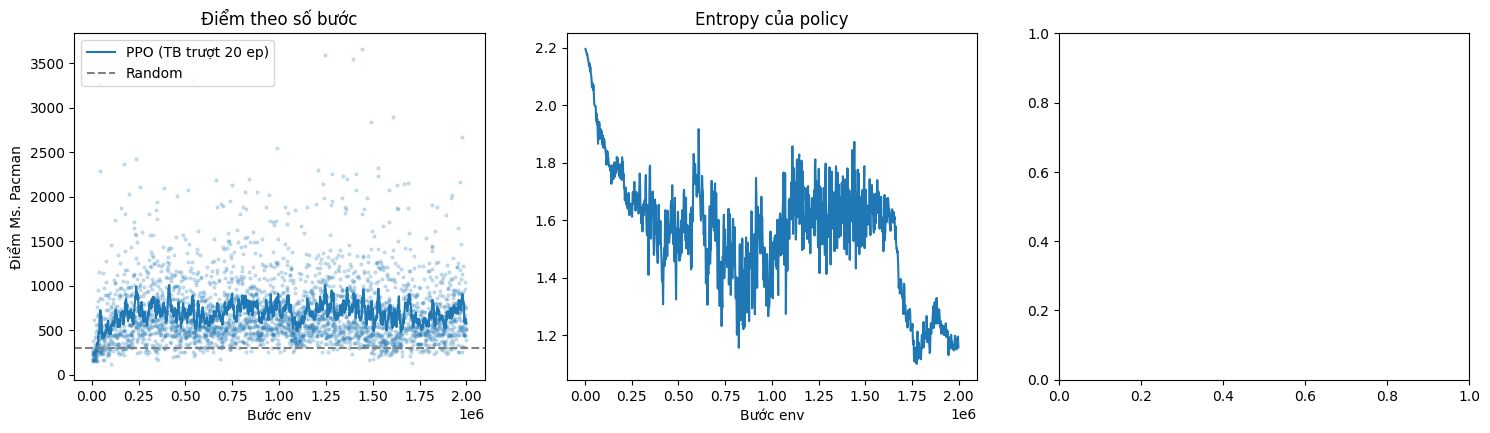

In [32]:
# Đường học của PPO (chưa cần DQN)
st, sc = zip(*ppo_eps)
x, y = curve(ppo_eps)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].scatter(st, sc, s=4, alpha=0.2, color="tab:blue")
ax[0].plot(x, y, color="tab:blue", label="PPO (TB trượt 20 ep)")
ax[0].axhline(np.mean(rand_scores), ls="--", color="gray", label="Random")
ax[0].set(title="Điểm theo số bước", xlabel="Bước env", ylabel="Điểm Ms. Pacman")
ax[0].legend()

ax[1].plot(ppo_log["step"], ppo_log["ent"], color="tab:blue")
ax[1].set(title="Entropy của policy", xlabel="Bước env")

x_ev, ev = events_per_bin(ppo_log, ppo_log["step"][-1])
ax[2].plot(x_ev, ev["pellets"], label="Viên năng lượng")
ax[2].plot(x_ev, ev["ghosts"], label="Ma")
ax[2].set(title="Sự kiện ăn được / 100k bước", xlabel="Bước env")
ax[2].legend()

plt.tight_layout(); plt.savefig(SAVE_DIR / "ms_pacman_ppo_curves.png", dpi=150); plt.show()